# Machine Learning at Scale with Spark ML Pipelines

**What you'll learn**

- The Spark ML object model — `Transformer`, `Estimator`, `Pipeline` — mapped 1:1 onto
  the sklearn concepts you already know, and *why* every Spark ML algorithm wants its
  input as a single vector column.
- A complete churn model in Spark: `StringIndexer` → `OneHotEncoder` →
  `VectorAssembler` → `StandardScaler` → `LogisticRegression` / `GBTClassifier`, with a
  correct train/test split and `BinaryClassificationEvaluator`.
- Hyperparameter search with `CrossValidator` + `ParamGridBuilder`: what the
  `parallelism` knob actually parallelizes, and how to extract per-combination metrics.
- The **metadata dance**: recovering feature names from the assembled vector's
  `ml_attr` metadata so coefficients and importances become readable — including where
  the metadata silently loses names and how to patch it.
- The scaling patterns that matter in practice: train-on-a-sample locally then score
  distributed (via `pandas_udf`) vs training distributed; pipeline persistence; writing
  predictions. Plus an honest sklearn-vs-Spark-ML comparison.

**Why it matters in interviews**

- "Design churn scoring for 500M users" is a staple system-design question for senior
  DS/AS roles — the strong answer is mostly about *when you don't need* distributed
  training, and this notebook builds that argument with measurements.
- Spark ML API questions ("what's an Estimator?", "why one features column?",
  "how does CrossValidator parallelize?") are quick screens for whether you've actually
  shipped Spark ML or just read about it.
- The metadata dance is a real day-one task on any Spark ML codebase ("which feature
  got this coefficient?") and a favorite practical probe.

**Honest scale note**: we simulate ~100k rows. That fits in RAM thousands of times
over — you would use sklearn/LightGBM for this in real life (see
`../04_ml_tabular/01_gradient_boosting_mastery.ipynb`). The point here is the *API and
the patterns*, which are identical at 100k and 5B rows; only the cluster changes. For
the engine itself (shuffles, joins, skew, tuning) see
`03_pyspark_fundamentals.ipynb`.

In [1]:
import os

# Cap native thread pools BEFORE importing numpy/sklearn. A local Spark JVM already
# uses both cores; an unbounded OpenMP pool on top oversubscribes the machine and can
# slow sklearn fits by ~100x (measured on this box: 27s -> 0.2s for the same fit).
os.environ.setdefault("OMP_NUM_THREADS", "2")

import json
import shutil
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from pyspark.sql.window import Window

rng = np.random.default_rng(42)  # house-style seeded RNG; Spark-side randomness is seeded per column

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 25)

spark = (
    SparkSession.builder
    .master("local[2]")                          # 2 local cores stand in for a cluster
    .appName("sparkml-churn-lab")
    .config("spark.ui.enabled", "false")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.shuffle.partitions", "8")  # default 200 is silly at this size
    .config("spark.driver.memory", "3g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/root/.ccr/java-truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12 -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=41191 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|anthropic.com|*.anthropic.com|*.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/root/.ccr/java-truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12 -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=41191 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|anthropic.com|*.anthropic.com|*.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/07/21 00:27:12 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/07/21 00:27:12 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/07/21 00:27:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0


## 1. Simulate a telco churn table — in Spark, with known ground truth

We generate ~100k customers *inside Spark* (`spark.range` + `F.rand(seed)` columns), the
way you would build test fixtures on a real cluster. Churn is drawn from a logistic
model whose coefficients **we choose**, so later we can check that the fitted model
recovers them — the simulation-first habit from
`../01_statistical_foundations/03_regression_the_workhorse.ipynb`.

Ground truth (log-odds scale):

| driver | effect | business story |
|---|---|---|
| month-to-month contract | +0.90 vs two-year | no lock-in, easy to leave |
| one-year contract | +0.15 vs two-year | mild lock-in |
| electronic check | +0.45 vs other payment | correlates with low engagement |
| fiber internet | +0.55 vs no internet | price-sensitive, competitive market |
| DSL internet | +0.25 vs no internet | |
| tenure | −0.035 per month | loyalty accumulates |
| monthly charges | +0.012 per $ | price pressure |
| support tickets | +0.22 per ticket | friction |
| senior citizen | +0.25 | |
| paperless billing | +0.15 | |
| **new customer (tenure ≤ 2)** | **+0.70** | onboarding-shock *kink* — deliberately **nonlinear** in tenure |
| streaming TV | 0.00 | pure noise feature |
| total charges | 0.00 | ≈ tenure × monthly charges — a deliberately redundant column |

Two booby traps are planted on purpose: `streaming_tv` and `total_charges` carry **no
effect** (though `total_charges` is highly correlated with real drivers), and the
new-customer kink is invisible to a model that is linear in tenure.

Determinism note: `F.rand(seed)` is seeded *per partition*, so results are reproducible
only if the partition layout is fixed — hence the explicit `numPartitions=4` in
`spark.range`, and the `.cache()` that freezes the table before anything downstream
touches it.

In [2]:
N = 100_000

TRUE_BETA = {
    "tenure_months": -0.035,
    "monthly_charges": 0.012,
    "total_charges": 0.0,
    "support_tickets": 0.22,
    "is_senior": 0.25,
    "paperless_billing": 0.15,
    "streaming_tv": 0.0,
    "contract=month_to_month": 0.90,
    "contract=one_year": 0.15,
    "contract=two_year": 0.0,
    "payment_method=electronic_check": 0.45,
    "payment_method=credit_card": 0.0,
    "payment_method=bank_transfer": 0.0,
    "payment_method=mailed_check": 0.0,
    "internet_service=fiber": 0.55,
    "internet_service=dsl": 0.25,
    "internet_service=none": 0.0,
}
NEW_CUSTOMER_KINK = 0.70   # extra log-odds when tenure_months <= 2 (nonlinear!)
INTERCEPT = -2.05

u = {name: F.rand(seed=101 + i) for i, name in enumerate(
    ["contract", "payment", "internet", "tenure", "monthly",
     "tickets", "senior", "paperless", "stream", "total", "churn"])}

df = (
    spark.range(0, N, 1, 4)                       # fixed partitioning -> reproducible rand()
    .withColumnRenamed("id", "customer_id")
    .withColumn(
        "contract",
        F.when(u["contract"] < 0.50, "month_to_month")
        .when(u["contract"] < 0.80, "one_year").otherwise("two_year"))
    .withColumn(
        "payment_method",
        F.when(u["payment"] < 0.30, "electronic_check")
        .when(u["payment"] < 0.60, "credit_card")
        .when(u["payment"] < 0.85, "bank_transfer").otherwise("mailed_check"))
    .withColumn(
        "internet_service",
        F.when(u["internet"] < 0.45, "fiber")
        .when(u["internet"] < 0.80, "dsl").otherwise("none"))
    .withColumn("tenure_months", (1 + F.floor(71 * F.pow(u["tenure"], 1.4))).cast("double"))
    .withColumn("is_senior", (u["senior"] < 0.16).cast("double"))
    .withColumn("paperless_billing", (u["paperless"] < 0.60).cast("double"))
    .withColumn("streaming_tv", (u["stream"] < 0.40).cast("double"))
    .withColumn(
        "monthly_charges",
        F.round(19 + F.when(F.col("internet_service") == "dsl", 30.0)
                      .when(F.col("internet_service") == "fiber", 55.0).otherwise(0.0)
                + 15 * u["monthly"] + 10 * F.col("streaming_tv"), 2))
    .withColumn(
        "total_charges",
        F.round(F.col("tenure_months") * F.col("monthly_charges")
                * (0.9 + 0.15 * u["total"]), 2))
    .withColumn(
        "support_tickets",
        F.least(F.floor(-1.2 * F.log(1 - u["tickets"])), F.lit(8)).cast("double"))
    .withColumn(
        "logit",
        F.lit(INTERCEPT)
        + TRUE_BETA["tenure_months"] * F.col("tenure_months")
        + TRUE_BETA["monthly_charges"] * F.col("monthly_charges")
        + TRUE_BETA["support_tickets"] * F.col("support_tickets")
        + TRUE_BETA["is_senior"] * F.col("is_senior")
        + TRUE_BETA["paperless_billing"] * F.col("paperless_billing")
        + F.when(F.col("contract") == "month_to_month", TRUE_BETA["contract=month_to_month"])
           .when(F.col("contract") == "one_year", TRUE_BETA["contract=one_year"]).otherwise(0.0)
        + F.when(F.col("payment_method") == "electronic_check",
                 TRUE_BETA["payment_method=electronic_check"]).otherwise(0.0)
        + F.when(F.col("internet_service") == "fiber", TRUE_BETA["internet_service=fiber"])
           .when(F.col("internet_service") == "dsl", TRUE_BETA["internet_service=dsl"]).otherwise(0.0)
        + F.when(F.col("tenure_months") <= 2, NEW_CUSTOMER_KINK).otherwise(0.0))
    .withColumn("true_p", 1 / (1 + F.exp(-F.col("logit"))))   # oracle column, never a feature
    .withColumn("churn", (u["churn"] < F.col("true_p")).cast("double"))
    .drop("logit")
    .cache()
)

n_rows = df.count()                                # materializes the cache
churn_rate = df.agg(F.avg("churn")).first()[0]
print(f"rows: {n_rows:,}   churn rate: {churn_rate:.4f}")

rows: 100,000   churn rate: 0.3196


In [3]:
# Sanity checks before modeling: do the planted effects show up in raw aggregates?
print(df.limit(5).toPandas().T.to_string(header=False), "\n")
print(df.select("tenure_months", "monthly_charges", "total_charges", "support_tickets")
        .summary("mean", "stddev", "min", "max").toPandas().to_string(index=False), "\n")
print(df.groupBy("contract")
        .agg(F.count("*").alias("n"), F.round(F.avg("churn"), 3).alias("churn_rate"))
        .orderBy("churn_rate").toPandas().to_string(index=False))

customer_id                       0            1               2            3             4
contract             month_to_month     one_year  month_to_month     one_year      one_year
payment_method     electronic_check  credit_card   bank_transfer  credit_card  mailed_check
internet_service               none          dsl             dsl        fiber           dsl
tenure_months                  22.0          4.0            41.0          7.0          10.0
is_senior                       0.0          0.0             0.0          0.0           0.0
paperless_billing               0.0          0.0             1.0          1.0           0.0
streaming_tv                    1.0          1.0             0.0          0.0           1.0
monthly_charges               32.99        60.01           53.82        86.78         63.12
total_charges                724.57       242.94         2254.58       606.23        646.21
support_tickets                 1.0          1.0             0.0          0.0   

summary     tenure_months   monthly_charges      total_charges    support_tickets
   mean          30.13726 68.40118109999989 2009.0833167000092             0.7704
 stddev 21.26675251278444 19.01446793391576 1577.3298227903085 1.1629004099120577
    min               1.0              19.0              17.43                0.0
    max              71.0              99.0            7363.91                8.0 



      contract     n  churn_rate
      two_year  9986       0.231
      one_year 40055       0.251
month_to_month 49959       0.392


## 2. Transformers, Estimators, Pipelines — the sklearn parallel

Spark ML is a deliberate clone of the sklearn design, with one renaming to memorize:

| concept | sklearn | Spark ML |
|---|---|---|
| stateless-ish step, `transform(df) → df` | transformer | `Transformer` |
| learns state: `fit(df) → model` | estimator (`fit` mutates `self`) | `Estimator` (`fit` **returns** a new `Model`, itself a `Transformer`) |
| chained steps | `Pipeline([...])` | `Pipeline(stages=[...])` |
| fitted chain | fitted `Pipeline` | `PipelineModel` |
| grid | `param_grid` dict | `ParamGridBuilder` |
| search | `GridSearchCV` | `CrossValidator` / `TrainValidationSplit` |

The one *structural* difference: sklearn passes a 2-D feature matrix alongside `y`;
Spark ML operates on a DataFrame and every algorithm reads **one column of type
`Vector`** (default name `features`) plus a label column. Why a single vector column?

- **One input contract for every algorithm.** Whether you have 10 features or 10
  million, the algorithm sees `(label, Vector)` rows — no per-column dispatch, and no
  3,000-column schemas (wide schemas are genuinely expensive in Catalyst/codegen).
- **Sparsity.** `Vector` has dense and sparse implementations; one-hot output stays
  sparse end-to-end, which is what makes 10M-dimensional feature spaces feasible.
- **Fast math.** Per-row BLAS operations on a contiguous array beat field-by-field
  access on a `Row`.
- **Metadata.** The vector column carries `ml_attr` metadata mapping slot → feature
  name. That is what makes coefficients interpretable later (section 6).

So the price of scale is *assembly plumbing*: `StringIndexer` (string → index) →
`OneHotEncoder` (index → sparse dummy vector) → `VectorAssembler` (columns → one
vector) → optional `StandardScaler`. Note that in Spark, `OneHotEncoder` and even
`StringIndexer` are **Estimators** — they learn vocabulary/category sizes at `fit`
time, exactly like sklearn's `OneHotEncoder.fit` learns categories.

In [4]:
from pyspark.ml import Estimator, Pipeline, PipelineModel, Transformer
from pyspark.ml.classification import GBTClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import (OneHotEncoder, StandardScaler, StringIndexer,
                                VectorAssembler)
from pyspark.ml.functions import vector_to_array
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

CAT_COLS = ["contract", "payment_method", "internet_service"]
NUM_COLS = ["tenure_months", "monthly_charges", "total_charges", "support_tickets"]
FLAG_COLS = ["is_senior", "paperless_billing", "streaming_tv"]

indexer = StringIndexer(
    inputCols=CAT_COLS, outputCols=[c + "_idx" for c in CAT_COLS],
    stringOrderType="frequencyDesc",   # index 0 = most frequent (the default, made explicit)
    handleInvalid="error",             # revisited in Pitfalls
)
encoder = OneHotEncoder(
    inputCols=[c + "_idx" for c in CAT_COLS],
    outputCols=[c + "_ohe" for c in CAT_COLS],   # dropLast=True default -> reference coding
)
num_assembler = VectorAssembler(inputCols=NUM_COLS, outputCol="num_raw")
scaler = StandardScaler(inputCol="num_raw", outputCol="num_scaled",
                        withMean=True, withStd=True)   # withMean is NOT the default — see Pitfalls
final_assembler = VectorAssembler(
    inputCols=["num_scaled"] + FLAG_COLS + [c + "_ohe" for c in CAT_COLS],
    outputCol="features",
)
lr = LogisticRegression(featuresCol="features", labelCol="churn", maxIter=100)

lr_pipeline = Pipeline(stages=[indexer, encoder, num_assembler, scaler,
                               final_assembler, lr])

for st in lr_pipeline.getStages():
    kind = "Estimator  (learns at fit)" if isinstance(st, Estimator) else "Transformer (stateless)"
    print(f"{type(st).__name__:<20} {kind}")

StringIndexer        Estimator  (learns at fit)
OneHotEncoder        Estimator  (learns at fit)
VectorAssembler      Transformer (stateless)
StandardScaler       Estimator  (learns at fit)
VectorAssembler      Transformer (stateless)
LogisticRegression   Estimator  (learns at fit)


Only `VectorAssembler` is a plain `Transformer` — everything else must *learn*
something from data (vocabularies, category sizes, means/stds, coefficients). We
scale only the numeric block and assemble the 0/1 flags and one-hot vectors around it:
scaling dummy variables buys nothing and destroys their sparsity.

## 3. Split correctly, fit end-to-end, evaluate

The split happens **before** any `fit` — the pipeline learns its indexers and scaler
statistics from training data only. Baking the transforms into the pipeline is what
makes this automatic; fitting transforms on the full dataset before splitting is the
classic subtle leak (see `../04_ml_tabular/02_leakage_validation.ipynb`).

`randomSplit` details worth knowing at interview depth:

- It's a **per-row Bernoulli draw**, not an exact partition — you get ~80/20, not
  exactly 80/20.
- Membership depends on the seed *and the physical partition layout* of the input. On
  a cached, fixed-layout DataFrame it's reproducible; on a re-computed shuffled input
  it may not be (demonstrated in Pitfalls, with a hash-based alternative).

In [5]:
train, test = df.randomSplit([0.8, 0.2], seed=42)
train = train.cache()
test = test.cache()
print(f"train: {train.count():,} rows  (churn {train.agg(F.avg('churn')).first()[0]:.4f})")
print(f"test:  {test.count():,} rows  (churn {test.agg(F.avg('churn')).first()[0]:.4f})")

train: 80,179 rows  (churn 0.3206)


test:  19,821 rows  (churn 0.3155)


In [6]:
t0 = time.time()
lr_model = lr_pipeline.fit(train)          # fits all 6 stages in order
lr_fit_s = time.time() - t0
print(f"pipeline fit in {lr_fit_s:.1f}s -> {type(lr_model).__name__} with stages:")
for st in lr_model.stages:
    print("   ", type(st).__name__)

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


pipeline fit in 22.6s -> PipelineModel with stages:
    StringIndexerModel
    OneHotEncoderModel
    VectorAssembler
    StandardScalerModel
    VectorAssembler
    LogisticRegressionModel


(`fit` triggers a one-time `netlib-blas` note about a missing native BLAS — Spark
falls back to JVM-implemented linear algebra, which is irrelevant at this scale.)

Every fitted stage is now a `Transformer` (`StringIndexerModel`, `StandardScalerModel`,
`LogisticRegressionModel`, ...), so `lr_model.transform(test)` replays the whole chain.
The output DataFrame gains three columns: `rawPrediction` (log-odds vector),
`probability` (class-probability vector) and `prediction` (thresholded 0/1).

In [7]:
lr_preds = lr_model.transform(test).cache()
lr_preds.select("customer_id", "churn", "probability", "prediction").show(5, truncate=False)
print("assembled features vector (one row):")
print(lr_preds.select("features").head()[0])

+-----------+-----+-----------------------------------------+----------+
|customer_id|churn|probability                              |prediction|
+-----------+-----+-----------------------------------------+----------+
|2          |0.0  |[0.8184949595043147,0.18150504049568528] |0.0       |
|6          |0.0  |[0.9432967316175471,0.056703268382452876]|0.0       |
|8          |0.0  |[0.7887693021169805,0.2112306978830195]  |0.0       |
|13         |1.0  |[0.678181280639147,0.32181871936085304]  |0.0       |
|19         |0.0  |[0.720762823483405,0.27923717651659496]  |0.0       |
+-----------+-----+-----------------------------------------+----------+
only showing top 5 rows
assembled features vector (one row):
[0.5110449766893121,-0.767534995099468,0.1550844591274899,-0.662095446561009,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0]


In [8]:
evaluator = BinaryClassificationEvaluator(labelCol="churn", rawPredictionCol="rawPrediction",
                                          metricName="areaUnderROC")
evaluator_pr = BinaryClassificationEvaluator(labelCol="churn", rawPredictionCol="rawPrediction",
                                             metricName="areaUnderPR")
auc_lr = evaluator.evaluate(lr_preds)
pr_lr = evaluator_pr.evaluate(lr_preds)
print(f"LogisticRegression   ROC-AUC: {auc_lr:.4f}   PR-AUC: {pr_lr:.4f}")

LogisticRegression   ROC-AUC: 0.7532   PR-AUC: 0.5769


`BinaryClassificationEvaluator` supports exactly two metrics — `areaUnderROC` and
`areaUnderPR` (prefer PR when positives are rare; see
`../04_ml_tabular/04_imbalanced_fraud.ipynb`). Accuracy, F1, logloss live in
`MulticlassClassificationEvaluator` — a perennial "why can't I get F1?" confusion.
One nuance we exploit in Exercise 2: the evaluator down-samples the curve to
`numBins` (default 1000), so its AUC is very slightly approximate.

## 4. GBTClassifier — and the precomputed-features pattern

`GBTClassifier` is Spark's distributed gradient-boosted trees. Same API, same
`features` column. Two practical notes:

- Refitting the *identical* feature stages for every model is wasteful. Since our
  transforms don't learn from the label, we can fit them **once** on train, materialize
  the `features` column, and iterate on models against the cached result. We reuse the
  already-fitted stages from `lr_model` by slicing them into a new `PipelineModel` —
  fitted stages are just objects.
- Trees don't need scaling or one-hot at all (a `StringIndexer`ed column plus vector
  metadata is enough — Spark's trees split categoricals natively). We keep the shared
  representation for comparability, but saying this unprompted is a senior signal.

In [9]:
feature_model = PipelineModel(stages=lr_model.stages[:-1])   # all fitted stages except LR

train_feats = feature_model.transform(train).select("customer_id", "churn", "features").cache()
test_feats = feature_model.transform(test).select("customer_id", "churn", "features").cache()
train_feats.count(), test_feats.count()                      # materialize

gbt = GBTClassifier(featuresCol="features", labelCol="churn",
                    maxIter=20, maxDepth=5, stepSize=0.1, seed=42)
t0 = time.time()
gbt_model = gbt.fit(train_feats)
gbt_fit_s = time.time() - t0
gbt_preds = gbt_model.transform(test_feats).cache()
auc_gbt = evaluator.evaluate(gbt_preds)
print(f"GBT fit in {gbt_fit_s:.1f}s   ROC-AUC: {auc_gbt:.4f}   "
      f"PR-AUC: {evaluator_pr.evaluate(gbt_preds):.4f}")

GBT fit in 21.5s   ROC-AUC: 0.7533   PR-AUC: 0.5839


GBT lands within a hair of logistic regression here — *as it should*: the ground truth
is a logistic model plus one small kink, so LR is essentially the Bayes-optimal model
family. Trees earn their keep when there are interactions and nonlinearities you
didn't hand-engineer. The interview-grade take: **always run the linear baseline**; if
boosted trees can't beat it, your signal is (near-)additive and you should ship the
simpler model. (For serious single-node boosting practice see
`../04_ml_tabular/01_gradient_boosting_mastery.ipynb`.)

## 5. CrossValidator + ParamGridBuilder

`CrossValidator` = sklearn's `GridSearchCV`, with one big architectural difference
worth being able to explain:

- **What `parallelism` parallelizes:** for each fold, the driver submits the fits for
  *all parameter combinations* to a thread pool of size `parallelism`. Each individual
  fit is still a fully distributed job; folds are processed sequentially. So
  `parallelism=2` means "up to 2 models training on the cluster at once" — it trades
  cluster scheduling pressure and memory for wall-clock time. This is *driver-side
  thread* parallelism, not sklearn's `n_jobs` process parallelism.
- `avgMetrics[i]` is the metric for `ParamGrid` entry `i` averaged over folds; after
  selection, the best combination is **refit on the full training set** — people
  forget the final refit exists.
- For expensive models on huge data, `TrainValidationSplit` (single random split) is
  the pragmatic alternative to k-fold.

The textbook form wraps the *entire* pipeline so every fold re-fits the transforms —
leak-proof by construction:

```python
cv = CrossValidator(estimator=lr_pipeline, ...)   # canonical, but refits indexers/scaler 12x
```

Here we cross-validate the bare `LogisticRegression` against the cached, precomputed
features instead — 12 LR fits instead of 12 six-stage pipeline fits. This is a common
production speedup and it is *almost* clean: our transforms never see the label, so the
only impurity is that indexer vocabularies and scaler statistics were computed on all
of train rather than per-fold — harmless here, but say it out loud when you do it.

In [10]:
grid = (
    ParamGridBuilder()
    .addGrid(lr.regParam, [0.01, 0.1])
    .addGrid(lr.elasticNetParam, [0.0, 0.5])   # 0 = ridge, 1 = lasso
    .build()
)
cv = CrossValidator(estimator=lr, estimatorParamMaps=grid, evaluator=evaluator,
                    numFolds=3, parallelism=2, seed=42)

t0 = time.time()
cv_model = cv.fit(train_feats)
print(f"CrossValidator: {len(grid)} combos x 3 folds = {3 * len(grid)} fits "
      f"in {time.time() - t0:.1f}s\n")

cv_results = pd.DataFrame(
    [{p.name: v for p, v in pm.items()} | {"mean_cv_auc": m}
     for pm, m in zip(grid, cv_model.avgMetrics)]
).sort_values("mean_cv_auc", ascending=False)
print(cv_results.to_string(index=False))

best_lr = cv_model.bestModel
print(f"\nbest: regParam={best_lr.getRegParam()}, "
      f"elasticNetParam={best_lr.getElasticNetParam()}")
print(f"test ROC-AUC of best model: {evaluator.evaluate(best_lr.transform(test_feats)):.4f}")

CrossValidator: 4 combos x 3 folds = 12 fits in 54.4s

 regParam  elasticNetParam  mean_cv_auc
     0.01              0.0     0.756827
     0.01              0.5     0.756666
     0.10              0.0     0.754307
     0.10              0.5     0.734468

best: regParam=0.01, elasticNetParam=0.0


test ROC-AUC of best model: 0.7526


Regularization buys nothing here — with 80k rows and 14 well-behaved features the
likelihood dominates any sane penalty, and the heaviest penalty (`regParam=0.1`,
elastic-net) visibly hurts. The grid exists to demonstrate mechanics; in real tuning,
spend your grid budget where curvature lives (tree depth, iterations, learning rate).

## 6. Inspect the model: the metadata dance

A `LogisticRegressionModel` gives you `coefficients` — a bare vector with **no names**.
The names live in the `features` column's `ml_attr` metadata, written by
`VectorAssembler`/`OneHotEncoder`. Walking `schema → metadata → attrs → idx/name` is
the "metadata dance" every Spark ML practitioner eventually memorizes.

One honest wrinkle: `StandardScaler` *drops* attribute names (its output is an
anonymous vector), so the slots that passed through it come back as `num_scaled_0`,
`num_scaled_1`, ... The fix is knowing that `VectorAssembler` preserves input order —
we re-attach `NUM_COLS` positionally. This is exactly the kind of sharp edge that
distinguishes "has done it" from "has read about it".

In [11]:
def feature_names(scored_df, col="features"):
    """The metadata dance: recover slot index -> feature name from ml_attr metadata."""
    attrs = scored_df.schema[col].metadata["ml_attr"]["attrs"]
    slots = sorted(
        [(a["idx"], a["name"]) for group in attrs.values() for a in group])
    names = []
    for idx, name in slots:
        if name.startswith("num_scaled_"):            # StandardScaler lost the names:
            names.append(NUM_COLS[int(name.rsplit("_", 1)[1])])   # re-attach by position
        elif "_ohe_" in name:                          # "contract_ohe_one_year" -> "contract=one_year"
            names.append(name.replace("_ohe_", "="))
        else:
            names.append(name)
    return names

names = feature_names(lr_preds)
print("raw metadata (before fixing):")
print(json.dumps(lr_preds.schema["features"].metadata["ml_attr"]["attrs"], indent=1)[:600], "...\n")
print("recovered slot names:", names)

# one-hot uses reference coding (dropLast=True): the least-frequent category is the baseline
for c, labels in zip(CAT_COLS, lr_model.stages[0].labelsArray):
    dropped = [x for x in labels if f"{c}={x}" not in names]
    print(f"dropped baseline for {c}: {dropped}")

raw metadata (before fixing):
{
 "binary": [
  {
   "name": "contract_ohe_month_to_month",
   "idx": 7
  },
  {
   "name": "contract_ohe_one_year",
   "idx": 8
  },
  {
   "name": "payment_method_ohe_credit_card",
   "idx": 9
  },
  {
   "name": "payment_method_ohe_electronic_check",
   "idx": 10
  },
  {
   "name": "payment_method_ohe_bank_transfer",
   "idx": 11
  },
  {
   "name": "internet_service_ohe_fiber",
   "idx": 12
  },
  {
   "name": "internet_service_ohe_dsl",
   "idx": 13
  }
 ],
 "numeric": [
  {
   "name": "num_scaled_0",
   "idx": 0
  },
  {
   "name": "num_scaled_1",
   "idx": 1
  },
  {
   "name": "num_s ...

recovered slot names: ['tenure_months', 'monthly_charges', 'total_charges', 'support_tickets', 'is_senior', 'paperless_billing', 'streaming_tv', 'contract=month_to_month', 'contract=one_year', 'payment_method=credit_card', 'payment_method=electronic_check', 'payment_method=bank_transfer', 'internet_service=fiber', 'internet_service=dsl']
dropped baseline for con

                        feature  beta_true  beta_hat  abs_err
                  tenure_months     -0.035   -0.0401   0.0051
                monthly_charges      0.012    0.0109   0.0011
                  total_charges      0.000    0.0000   0.0000
                support_tickets      0.220    0.2199   0.0001
                      is_senior      0.250    0.2271   0.0229
              paperless_billing      0.150    0.1444   0.0056
                   streaming_tv      0.000   -0.0029   0.0029
        contract=month_to_month      0.900    0.9198   0.0198
              contract=one_year      0.150    0.1528   0.0028
     payment_method=credit_card      0.000    0.0033   0.0033
payment_method=electronic_check      0.450    0.4589   0.0089
   payment_method=bank_transfer      0.000    0.0423   0.0423
         internet_service=fiber      0.550    0.6544   0.1044
           internet_service=dsl      0.250    0.3199   0.0699

intercept: -2.168  (true -2.05, not comparable 1:1 — reference catego

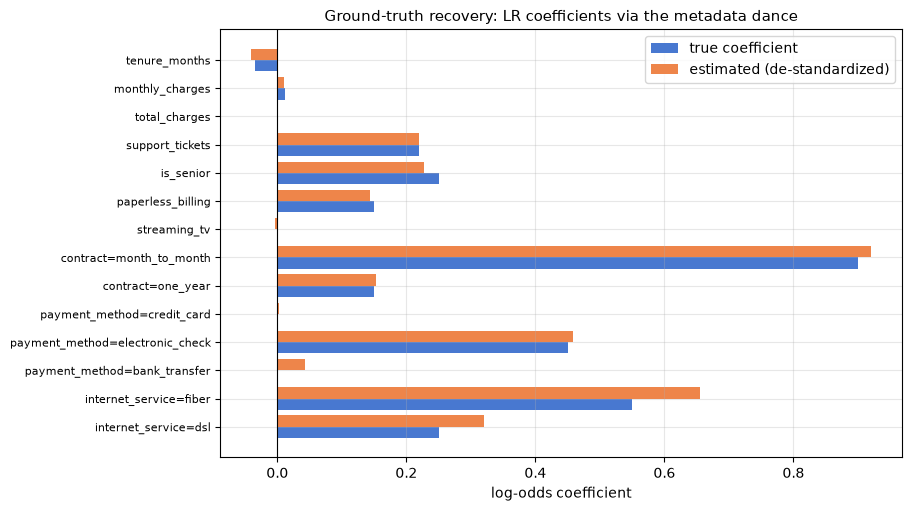

In [12]:
# De-standardize: coefficients for scaled slots are per-standard-deviation; divide by the
# training std (from the fitted scaler) to return to natural units, then compare to truth.
lr_stage = lr_model.stages[-1]
stds = lr_model.stages[3].std.toArray()               # StandardScalerModel
coefs = lr_stage.coefficients.toArray().copy()
coefs[: len(NUM_COLS)] = coefs[: len(NUM_COLS)] / stds

recovery = (
    pd.DataFrame({"feature": names, "beta_hat": coefs})
    .merge(pd.Series(TRUE_BETA, name="beta_true").rename_axis("feature").reset_index(),
           on="feature", how="left")
    .assign(abs_err=lambda d: (d.beta_hat - d.beta_true).abs())
    [["feature", "beta_true", "beta_hat", "abs_err"]]
)
print(recovery.round(4).to_string(index=False))
print(f"\nintercept: {lr_stage.intercept:.3f}  (true {INTERCEPT}, "
      "not comparable 1:1 — reference categories and the kink shift it)")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(recovery))
ax.barh(y + 0.2, recovery.beta_true, height=0.4, label="true coefficient", color="#4878d0")
ax.barh(y - 0.2, recovery.beta_hat, height=0.4, label="estimated (de-standardized)", color="#ee854a")
ax.set_yticks(y, recovery.feature, fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("log-odds coefficient")
ax.set_title("Ground-truth recovery: LR coefficients via the metadata dance")
ax.legend()
plt.show()

Reading this like a senior candidate:

- **The zero-effect features are recovered as ≈0**: `streaming_tv` and — despite being
  nearly collinear with tenure × monthly charges — `total_charges`. Regression
  conditions on the other columns; it does not get fooled by marginal correlation.
- **The tenure slope is steeper than truth** (≈ −0.040 vs −0.035). That is the omitted
  new-customer kink being absorbed into the linear term — a *specification* bias, not
  an estimation error. Exercise 1 fixes it with one engineered flag.
- **Correlated features share credit**: `monthly_charges` is partly determined by
  `internet_service`, so a bit of the per-dollar effect migrates onto the
  fiber/DSL dummies. Predictions are unaffected; per-coefficient stories are — the
  same caveat as `../04_ml_tabular/05_explainability_shap.ipynb`.
- One-hot coefficients are **contrasts against the dropped baseline** (least-frequent
  category under `frequencyDesc` + `dropLast`). We chose zero-effect baselines so the
  numbers match directly.

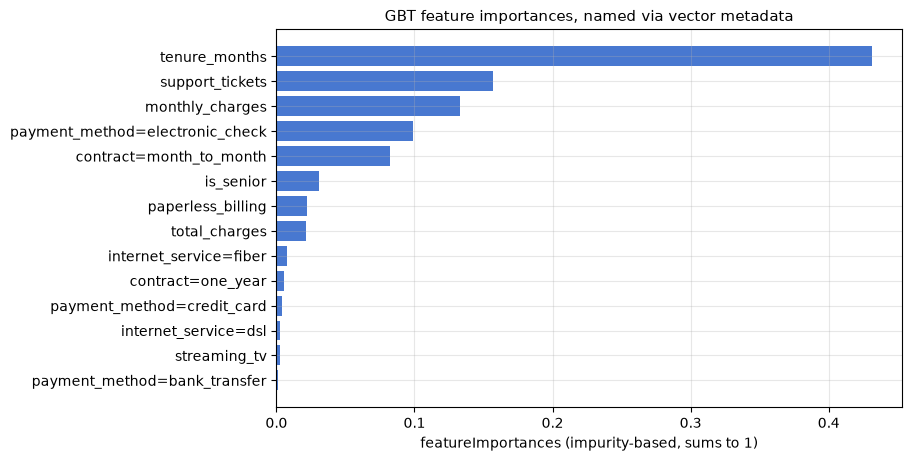

                        feature  importance
                  tenure_months       0.431
                support_tickets       0.157
                monthly_charges       0.133
payment_method=electronic_check       0.099
        contract=month_to_month       0.082
                      is_senior       0.031


In [13]:
# Same dance for GBT importances (impurity-based, normalized to sum to 1).
imp = pd.DataFrame({"feature": names,
                    "importance": gbt_model.featureImportances.toArray()})
imp = imp.sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.feature, imp.importance, color="#4878d0")
ax.set_xlabel("featureImportances (impurity-based, sums to 1)")
ax.set_title("GBT feature importances, named via vector metadata")
plt.show()
print(imp.sort_values("importance", ascending=False).head(6).round(3).to_string(index=False))

Note the contrast with LR: the GBT gives `total_charges` *non-zero* importance — trees
happily split on a redundant proxy, and impurity importance rewards it. Importance ≠
effect, and importance is not a causal statement; when this matters, reach for
permutation importance or SHAP (`../04_ml_tabular/05_explainability_shap.ipynb`).

### Score distributions and a confusion matrix at a business threshold

`probability` is a 2-slot vector; `vector_to_array(...)[1]` extracts P(churn) as a
plain double — the standard idiom. For the operating threshold we take a *capacity*
view: the retention team can call ~20% of customers, so flag the top quintile of risk
(threshold economics done properly is `../04_ml_tabular/03_evaluation_calibration.ipynb`).

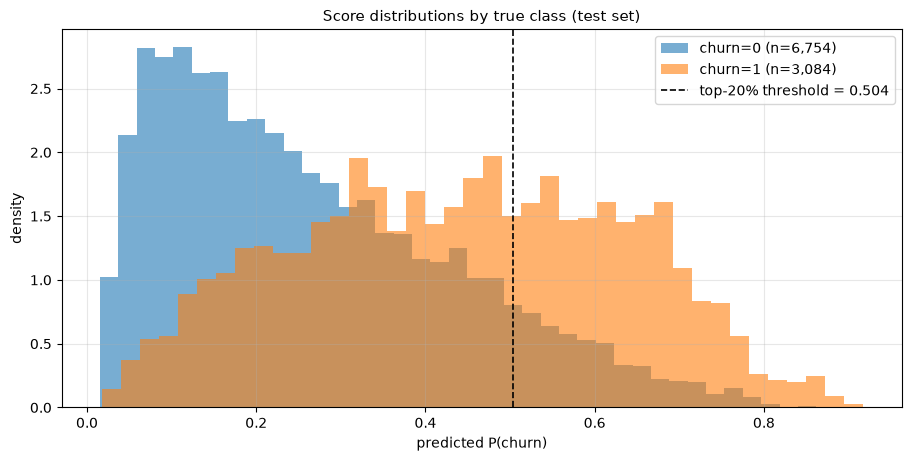

In [14]:
scored = lr_preds.withColumn("p_churn", vector_to_array("probability")[1])

plot_pdf = scored.select("p_churn", "churn").sample(0.5, seed=3).toPandas()
thr = scored.approxQuantile("p_churn", [0.8], 0.001)[0]   # top-20% capacity threshold

fig, ax = plt.subplots()
for label, sub in plot_pdf.groupby("churn"):
    ax.hist(sub.p_churn, bins=40, alpha=0.6, density=True,
            label=f"churn={int(label)} (n={len(sub):,})")
ax.axvline(thr, color="k", ls="--", lw=1.2, label=f"top-20% threshold = {thr:.3f}")
ax.set_xlabel("predicted P(churn)")
ax.set_ylabel("density")
ax.set_title("Score distributions by true class (test set)")
ax.legend()
plt.show()

In [15]:
cm = (scored.withColumn("flagged", (F.col("p_churn") >= thr).cast("int"))
      .groupBy("churn", "flagged").count().toPandas()
      .pivot(index="churn", columns="flagged", values="count"))
tn, fp = cm.loc[0.0, 0], cm.loc[0.0, 1]
fn, tp = cm.loc[1.0, 0], cm.loc[1.0, 1]
base = (tp + fn) / (tn + fp + fn + tp)
precision, recall = tp / (tp + fp), tp / (tp + fn)
print(cm, "\n")
print(f"precision @ top-20%: {precision:.3f}   recall: {recall:.3f}   "
      f"lift vs base rate ({base:.3f}): {precision / base:.2f}x")

flagged      0     1
churn               
0.0      12045  1522
1.0       3795  2459 

precision @ top-20%: 0.618   recall: 0.393   lift vs base rate (0.316): 1.96x


The overlap between the two histograms is irreducible: even the *oracle* model (we know
`true_p`) could not separate these classes cleanly, because churn is genuinely
stochastic. A candidate who says "AUC 0.75, can we get to 0.95?" without asking what
the Bayes ceiling might be is optimizing noise.

## 7. Patterns at scale

### Pattern A: train on a sample locally, score distributed

The most under-asked question in "big data ML" is: *does the training set actually
need to be big?* With ~32% churn, a 20k-row sample contains ~6.5k positive examples —
plenty to estimate a dozen effects. The standard senior play:

1. build features in Spark (that part genuinely needs the cluster),
2. sample to a pandas DataFrame and train with sklearn/LightGBM locally
   (mature algorithms, fast iteration, SHAP, calibration tooling),
3. ship the model back into Spark with a `pandas_udf` for distributed scoring —
   scoring is embarrassingly parallel.

When sampling *loses*: very rare positives (keep all positives, downsample negatives,
recalibrate — `../04_ml_tabular/04_imbalanced_fraud.ipynb`), high-cardinality
memorization features (user embeddings), or when the sample can't fit the long tail of
categories. None apply here, and mostly they argue for *smarter sampling*, not
distributed training.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder as SkOneHotEncoder

FEATURES = CAT_COLS + NUM_COLS + FLAG_COLS

sample_pdf = (train.select(*FEATURES, "churn")
              .sample(fraction=0.25, seed=7).toPandas())      # ~20k rows to the driver
print(f"local sample: {len(sample_pdf):,} rows, "
      f"{sample_pdf.churn.sum():.0f} positives")

sk_model = SkPipeline([
    ("prep", ColumnTransformer([("cat", SkOneHotEncoder(handle_unknown="ignore"), CAT_COLS)],
                               remainder="passthrough")),
    ("gbm", HistGradientBoostingClassifier(max_iter=150, random_state=42)),
])
t0 = time.time()
sk_model.fit(sample_pdf[FEATURES], sample_pdf["churn"])
sk_fit_s = time.time() - t0
print(f"sklearn HistGBM fit on the sample: {sk_fit_s:.2f}s")

local sample: 20,114 rows, 6471 positives


sklearn HistGBM fit on the sample: 1.12s


In [17]:
# Distributed scoring of the local model: the closure pickles sk_model into each task
# (use sc.broadcast for models >~10MB). Arrow moves data in vectorized batches.
@F.pandas_udf(DoubleType())
def sk_score(*cols: pd.Series) -> pd.Series:
    X = pd.concat(cols, axis=1)
    X.columns = FEATURES
    return pd.Series(sk_model.predict_proba(X)[:, 1])

sk_scored = test.withColumn("sk_p", sk_score(*[F.col(c) for c in FEATURES]))
auc_sk = BinaryClassificationEvaluator(labelCol="churn", rawPredictionCol="sk_p").evaluate(sk_scored)

comparison = pd.DataFrame([
    {"approach": "Spark GBTClassifier, distributed fit on 80k rows",
     "fit_seconds": round(gbt_fit_s, 1), "test_ROC_AUC": round(auc_gbt, 4)},
    {"approach": "sklearn HistGBM, local fit on 20k sample",
     "fit_seconds": round(sk_fit_s, 1), "test_ROC_AUC": round(auc_sk, 4)},
])
print(comparison.to_string(index=False))

                                        approach  fit_seconds  test_ROC_AUC
Spark GBTClassifier, distributed fit on 80k rows         21.5        0.7533
        sklearn HistGBM, local fit on 20k sample          1.1        0.7476


The locally-trained model matches the distributed one to within ~0.006 AUC while
fitting **an order of magnitude faster** (timings above) — and that gap *widens* on
real clusters, where each distributed tree costs network round-trips per split. Distributed
training earns its complexity only when (a) the model demonstrably improves with more
rows than one machine holds, (b) positives are so rare that any manageable sample
starves the model, or (c) the feature matrix itself (e.g., 10M sparse dims) can't fit.
If you truly need distributed boosting, prefer `xgboost.spark` / LightGBM-on-Spark
over `GBTClassifier` — better algorithms, same cluster.

### Pattern B: pipeline persistence and batch scoring

`PipelineModel.save` writes a directory tree (JSON params + Parquet data per stage) —
language-agnostic, so a model trained in PySpark loads from Scala and vice versa.
This is the unit you hand to a nightly scoring job. It is **not** a low-latency
serving format: for online serving you export (ONNX), re-implement the scoring
formula (routine for GLMs/scorecards — see
`../09_finance_and_operations/01_credit_scorecard.ipynb`), or use a serving-oriented
runtime.

Parity-check a reloaded model on **parameters or predictions**, not on a re-computed
evaluator AUC: the evaluator's default 1000-bin curve downsampling depends on the
physical partition layout of the scored data, so even bit-identical scores can move
the AUC in the 6th decimal between runs — a cousin of Pitfall 2 below.

In [18]:
MODEL_DIR = tempfile.mkdtemp(prefix="sparkml_lab_")
model_path = os.path.join(MODEL_DIR, "churn_lr_pipeline")

lr_model.write().overwrite().save(model_path)
reloaded = PipelineModel.load(model_path)

# Proper parity check: params round-trip exactly (doubles in Parquet), so the reloaded
# pipeline must reproduce the original probabilities bit-for-bit.
same_coefs = np.array_equal(lr_model.stages[-1].coefficients.toArray(),
                            reloaded.stages[-1].coefficients.toArray())
rel_p = (reloaded.transform(test)
         .select("customer_id", vector_to_array("probability")[1].alias("p_rel")))
n_diff = (scored.select("customer_id", "p_churn").join(rel_p, "customer_id")
          .where(F.col("p_churn") != F.col("p_rel")).count())
print(f"coefficients identical after reload: {same_coefs}")
print(f"rows where reloaded probability != original (exact compare): {n_diff}\n")

print("on-disk layout (first entries):")
for p in sorted(os.path.relpath(os.path.join(r, x), MODEL_DIR)
                for r, ds, fs in os.walk(MODEL_DIR) for x in ds + fs)[:12]:
    print("  ", p)

coefficients identical after reload: True
rows where reloaded probability != original (exact compare): 0

on-disk layout (first entries):
   churn_lr_pipeline
   churn_lr_pipeline/metadata
   churn_lr_pipeline/metadata/._SUCCESS.crc
   churn_lr_pipeline/metadata/.part-00000-b328631e-3ca6-4b4e-b9c1-5f374590e5f7-c000.txt.crc
   churn_lr_pipeline/metadata/_SUCCESS
   churn_lr_pipeline/metadata/part-00000-b328631e-3ca6-4b4e-b9c1-5f374590e5f7-c000.txt
   churn_lr_pipeline/stages
   churn_lr_pipeline/stages/0_StringIndexer_430335cab69d
   churn_lr_pipeline/stages/0_StringIndexer_430335cab69d/data
   churn_lr_pipeline/stages/0_StringIndexer_430335cab69d/data/._SUCCESS.crc
   churn_lr_pipeline/stages/0_StringIndexer_430335cab69d/data/.part-00000-cb09f030-bdb6-489e-b22d-dda2beaf413a-c000.snappy.parquet.crc
   churn_lr_pipeline/stages/0_StringIndexer_430335cab69d/data/_SUCCESS


In [19]:
# Writing predictions — the normal end state of a batch scoring job. In production this
# would be partitioned by score_date and land in the warehouse.
preds_path = os.path.join(MODEL_DIR, "churn_scores.parquet")
(scored.select("customer_id", "p_churn", "prediction")
 .write.mode("overwrite").parquet(preds_path))
back = spark.read.parquet(preds_path)
print(f"wrote and re-read {back.count():,} scored rows; sample:")
back.orderBy(F.desc("p_churn")).show(5)

wrote and re-read 19,821 scored rows; sample:


+-----------+------------------+----------+
|customer_id|           p_churn|prediction|
+-----------+------------------+----------+
|      13740|0.9230923564071217|       1.0|
|      31336|0.9176850494241028|       1.0|
|      99184|0.8997867416160371|       1.0|
|      25828|0.8958175786845539|       1.0|
|      28383|0.8939185687952673|       1.0|
+-----------+------------------+----------+
only showing top 5 rows


## 8. sklearn vs Spark ML — the honest comparison

| dimension | sklearn (+ xgboost/lightgbm) | Spark ML |
|---|---|---|
| algorithm coverage | enormous: SVMs, GPs, isolation forests, calibration, quantile models, the whole boosting ecosystem | deliberately small: GLMs, trees/RF/GBT, ALS, k-means/LDA, basic stats |
| API maturity | rich metrics, `Pipeline`, `ColumnTransformer`, halving/random search, years of ergonomic polish | functional but verbose; vector plumbing; 2 binary metrics in the evaluator |
| data scale | one machine's RAM (≈ tens of GB; `partial_fit` for some out-of-core) | horizontal — TB+ feature building and scoring are the actual superpower |
| speed at small/medium scale | 10–100x faster (measured above) | JVM + scheduling overhead per iteration |
| model inspection | SHAP, calibration curves, everything | coefficients/importances + the metadata dance; export for anything fancy |
| hyperparameter search | grid/random/halving + optuna ecosystem | grid only (`CrossValidator`, `TrainValidationSplit`) |
| deployment | pickle/ONNX; sub-ms online scoring | directory-format models; great for batch, wrong tool for online serving |
| **wins when** | data (or a sufficient sample) fits on one box — the overwhelmingly common case | features/scoring genuinely span a cluster; one JVM stack end-to-end; nightly batch over billions of rows |

The mature stance: they're not competitors — Spark builds features and scores at
scale; the model in the middle is trained wherever iteration is fastest.

## 9. Pitfalls

### Pitfall 1: unseen categories at transform time

`StringIndexer(handleInvalid="error")` (the default) throws the moment scoring data
contains a label unseen at fit time — the classic "the nightly job died because
marketing launched a new payment method". `"keep"` routes unseen labels to a reserved
extra index; `"skip"` silently drops the rows (dangerous default to reach for).

In [20]:
new_customers = spark.createDataFrame(
    [("month_to_month", "crypto_wallet", "fiber")], CAT_COLS)   # unseen payment method

spark.sparkContext.setLogLevel("OFF")   # silence the expected executor stack trace
try:
    lr_model.stages[0].transform(new_customers).collect()
except Exception as e:
    msg = str(e)
    start = msg.find("Unseen label")
    print("handleInvalid='error' ->", msg[start:start + 80], "...")
finally:
    spark.sparkContext.setLogLevel("ERROR")

idx_keep = StringIndexer(inputCol="payment_method", outputCol="payment_idx",
                         handleInvalid="keep").fit(train)
ohe_keep = OneHotEncoder(inputCols=["payment_idx"], outputCols=["payment_ohe"]).fit(
    idx_keep.transform(train))
out = ohe_keep.transform(idx_keep.transform(new_customers))
print("\nhandleInvalid='keep':")
out.select("payment_method", "payment_idx", "payment_ohe").show(truncate=False)
print("categorySizes with keep:", ohe_keep.categorySizes,
      "(4 real categories + 1 reserved unknown slot)")

handleInvalid='error' -> Unseen label: crypto_wallet. To handle unseen labels, set Param handleInvalid to ...



handleInvalid='keep':
+--------------+-----------+-----------+
|payment_method|payment_idx|payment_ohe|
+--------------+-----------+-----------+
|crypto_wallet |4.0        |(4,[],[])  |
+--------------+-----------+-----------+

categorySizes with keep: [5] (4 real categories + 1 reserved unknown slot)


Subtlety worth saying in an interview: with `keep`, `dropLast=True` drops the
*unknown* slot (unseen rows encode as all-zeros), so **all real categories keep a
dummy** — you've silently moved from reference coding to full one-hot. For an
unregularized GLM that makes the dummies + intercept perfectly collinear:
individual coefficients lose their "contrast vs baseline" meaning even though
predictions are fine. Robust production alternative: bucket rare/unknown categories
into an explicit `__other__` during feature engineering, so the encoding is stable
*and* interpretable.

### Pitfall 2: `randomSplit` membership depends on physical layout

Same data, same seed — but repartitioning changes which rows land in train.
`randomSplit` draws per-partition, so the split is only reproducible while the
partition layout is. A hash of a stable key is layout-proof (and is also how you get
consistent splits across *days* of reruns).

In [21]:
split_a = df.randomSplit([0.8, 0.2], seed=42)[0].select("customer_id")
split_b = df.repartition(16).randomSplit([0.8, 0.2], seed=42)[0].select("customer_id")
moved = split_a.exceptAll(split_b).count()
print(f"rows in train under layout A but not layout B (same seed!): {moved:,}")

hash_a = df.where(F.pmod(F.xxhash64("customer_id"), F.lit(100)) < 80).select("customer_id")
hash_b = (df.repartition(16)
          .where(F.pmod(F.xxhash64("customer_id"), F.lit(100)) < 80).select("customer_id"))
print(f"hash-based split, disagreement across layouts: {hash_a.exceptAll(hash_b).count()}")

rows in train under layout A but not layout B (same seed!): 15,949


hash-based split, disagreement across layouts: 0


### Pitfall 3: `StandardScaler` does not center by default

Spark's `StandardScaler` defaults to `withMean=False` — it divides by the std but does
**not** subtract the mean, the opposite of sklearn's default. The reason is
respectable (subtracting a mean densifies sparse vectors — catastrophic on a
10M-dimensional one-hot space), but if you assumed z-scores, your "standardized"
features still carry their full offset.

In [22]:
num_raw = num_assembler.transform(train)
default_scaled = StandardScaler(inputCol="num_raw", outputCol="scaled").fit(num_raw) \
    .transform(num_raw).select(vector_to_array("scaled").alias("a"))
m = default_scaled.agg(*[F.avg(F.col("a")[i]).alias(NUM_COLS[i]) for i in range(len(NUM_COLS))]) \
    .toPandas().T.rename(columns={0: "mean_after_default_scaling"})
print(m.round(3).to_string(), "\n^ not zero-centered: default is withMean=False (sklearn centers by default)")

                 mean_after_default_scaling
tenure_months                         1.416
monthly_charges                       3.598
total_charges                         1.273
support_tickets                       0.662 
^ not zero-centered: default is withMean=False (sklearn centers by default)


### Pitfall 4: the `prediction` column is a 0.5-threshold in disguise

`LogisticRegressionModel` bakes `threshold=0.5` into `prediction`. Here that flags
~20% of customers — by *coincidence* almost exactly our top-20% capacity point,
because a 32% base rate happens to put the score distribution's 80th percentile at
0.504. The coincidence is fragile: at a 10% call capacity the operating threshold
moves well above 0.5 (measured below), and at fraud-like base rates (1–3%) a 0.5
threshold flags nobody at all. Derive the threshold from capacity or cost economics,
or ignore `prediction` and threshold `probability` yourself (as in section 6).

In [23]:
print("default threshold:", lr_stage.getThreshold())
flagged_default = lr_preds.agg(F.avg("prediction")).first()[0]

thr10 = scored.approxQuantile("p_churn", [0.9], 0.001)[0]   # 10%-capacity operating point
lr_stage.setThreshold(float(thr10))
flagged_capacity = lr_model.transform(test).agg(F.avg("prediction")).first()[0]
lr_stage.setThreshold(0.5)                   # restore the default
print(f"share flagged @0.5: {flagged_default:.3f}   "
      f"@top-10% capacity threshold {thr10:.3f}: {flagged_capacity:.3f}")

default threshold: 0.5


share flagged @0.5: 0.205   @top-10% capacity threshold 0.609: 0.101


One more that needs no demo: `toPandas()` collects the entire DataFrame to the driver.
On real data that's an OOM; always `sample()`/`limit()` first (every collect in this
notebook does), and remember aggregation-then-collect beats collect-then-aggregate.

## 10. Interview corner

**1. "Design churn scoring for 500M users."**
Strong answer skeleton: (a) *Features* — event logs → warehouse aggregation in
Spark/SQL; a daily feature-build job is where distribution is genuinely mandatory
(500M × 200 features ≈ 400+ GB, joins over TB of events). (b) *Training* — churn has a
healthy base rate, so a stratified sample of 5–20M rows trains a LightGBM on one large
box; argue distributed training is unnecessary before describing how you'd do it
(xgboost-on-Spark) if pressed. (c) *Scoring* — embarrassingly parallel: broadcast
model + `pandas_udf`, or a saved `PipelineModel`, writing partitioned Parquet daily.
(d) *Ops* — backtesting with time-based splits, calibration checks, drift monitors,
retrain cadence (`../10_ml_in_production/01_drift_monitoring.ipynb`). Bonus points for
defining the label window rigorously (churn within 30d of snapshot, features strictly
pre-snapshot — `../08_product_analytics/02_churn_survival.ipynb`).

**2. "Why does Spark ML put all features in one vector column?"**
One input contract (`label`, `Vector`) for every algorithm regardless of feature
count; avoids thousands-of-columns schemas that stress Catalyst/codegen; the Vector
type supports sparse representation so one-hot spaces stay cheap; per-row math runs on
contiguous arrays; slot→name mapping travels in `ml_attr` metadata.

**3. "How does CrossValidator parallelize?"**
Folds are sequential; within a fold, the driver launches fits for parameter
combinations concurrently from a thread pool of size `parallelism`; every fit is
itself a distributed job. So total concurrency = `parallelism` × cluster; the limit is
executor memory and scheduler pressure, and `avgMetrics` + a final refit on all of
train give you the selected model.

**4. "When would you NOT train distributed?"**
Almost always, once features are built: if a representative sample fits on one machine,
local libraries are faster per iteration, algorithmically better (LightGBM/XGBoost vs
`GBTClassifier`), easier to debug, and richer to interpret. Distribute training only
for genuinely irreducible scale (billions of rows that measurably help, huge sparse
dims, matrix factorization on full interaction data) — and even then prefer
`xgboost.spark` over the built-ins for boosting.

**5. "Your sklearn model must score 2B rows nightly — options?"**
`pandas_udf`/`mapInPandas` with the model broadcast (simplest, shown above); export to
ONNX and score in the JVM; or for GLMs/scorecards, compile the model to a SQL
expression and let the warehouse do it — zero new infrastructure.

**6. "How do you handle categories unseen at training time?"**
In Spark: `handleInvalid="keep"` (reserved slot; know the `dropLast` interaction) or
`"skip"` (drops rows — rarely what you want). More robust: frequency-threshold
bucketing to `__other__` in feature engineering, or hashing for very high cardinality;
monitor the unseen-rate as a drift signal.

## 11. Key takeaways

- Spark ML ≈ sklearn with renamed nouns: `Estimator.fit → Model`, models are
  `Transformer`s, `Pipeline` chains them; the real difference is the single assembled
  `features` vector column (contract, sparsity, metadata).
- Fit the pipeline on train only; `randomSplit` is Bernoulli **and layout-dependent** —
  cache first, or hash a stable key for layout-proof splits.
- `CrossValidator`'s `parallelism` = concurrent *model fits* driven from the driver;
  folds are sequential; the best combo is refit on all of train.
- Coefficients and importances come back nameless; recover names via the vector's
  `ml_attr` metadata, and know that `StandardScaler` drops names (re-attach
  positionally) and that coefficients on scaled slots need de-standardizing.
- On (near-)additive ground truth, LR matches GBT — always run the linear baseline
  before reaching for trees.
- Train-on-sample locally + score distributed beats distributed training in most real
  settings; here the local model matched the distributed one to ~0.006 AUC while
  fitting an order of magnitude faster.
- `PipelineModel.save/load` gives language-agnostic batch-scoring artifacts — not an
  online-serving format.
- Defaults that bite: `handleInvalid="error"`, `withMean=False`, `threshold=0.5`,
  evaluator has only ROC/PR metrics.

## 12. Exercises

**Exercise 1.** The ground truth includes a +0.70 log-odds spike for customers with
`tenure_months ≤ 2` that our linear pipeline can't represent. Add an engineered
`is_new_customer` flag, refit the logistic regression, and check (a) the tenure
coefficient moves back toward its true −0.035, (b) the flag's coefficient recovers
≈ +0.70, (c) how much test AUC improves.

**Exercise 2.** Compute the exact ROC-AUC of the LR model "by hand" in Spark using the
rank-sum (Mann–Whitney) identity
AUC = (Σ ranks of positives − n₊(n₊+1)/2) / (n₊ n₋), and compare it to
`BinaryClassificationEvaluator` with default `numBins=1000` and with `numBins=0`
(exact). Which setting reproduces the hand computation, and where does the
approximation in the other come from?

**Exercise 3.** Calibration check in Spark: bucket test predictions into deciles of
`p_churn` and compare mean predicted probability vs observed churn rate per decile
(we kept the oracle `true_p` column — add it to the comparison). Should a logistic
model fit on logistic ground truth be calibrated?

In [24]:
# --- Solution 1 ---
train2 = train.withColumn("is_new_customer", (F.col("tenure_months") <= 2).cast("double"))
test2 = test.withColumn("is_new_customer", (F.col("tenure_months") <= 2).cast("double"))

assembler2 = VectorAssembler(
    inputCols=["num_scaled"] + FLAG_COLS + ["is_new_customer"] + [c + "_ohe" for c in CAT_COLS],
    outputCol="features2")
lr2 = LogisticRegression(featuresCol="features2", labelCol="churn", maxIter=100)

# reuse the already-fitted feature stages, add the new assembler, fit only the LR
tf_train2 = assembler2.transform(feature_model.transform(train2))
tf_test2 = assembler2.transform(feature_model.transform(test2))
lr2_model = lr2.fit(tf_train2)

names2 = feature_names(tf_test2, "features2")
coefs2 = lr2_model.coefficients.toArray().copy()
coefs2[: len(NUM_COLS)] = coefs2[: len(NUM_COLS)] / stds

i_tenure, i_new = names2.index("tenure_months"), names2.index("is_new_customer")
auc_lr2 = BinaryClassificationEvaluator(labelCol="churn").evaluate(lr2_model.transform(tf_test2))
print(f"tenure coefficient:  without flag {recovery.set_index('feature').loc['tenure_months', 'beta_hat']:+.4f}"
      f"  ->  with flag {coefs2[i_tenure]:+.4f}   (true −0.035)")
print(f"is_new_customer coefficient: {coefs2[i_new]:+.3f}   (true +0.70)")
print(f"test ROC-AUC: {auc_lr:.4f} -> {auc_lr2:.4f}")
print("\nThe specification bias vanishes once the kink is representable. AUC barely "
      "moves:\nthe steeper linear slope had already soaked up most of the kink's "
      "*ranking* signal —\ncorrect coefficients and good discrimination are different goals.")

tenure coefficient:  without flag -0.0401  ->  with flag -0.0344   (true −0.035)
is_new_customer coefficient: +0.636   (true +0.70)
test ROC-AUC: 0.7532 -> 0.7567

The specification bias vanishes once the kink is representable. AUC barely moves:
the steeper linear slope had already soaked up most of the kink's *ranking* signal —
correct coefficients and good discrimination are different goals.


In [25]:
# --- Solution 2 ---
# Exact AUC via Mann–Whitney: P(score_pos > score_neg). Global Window -> single
# partition; fine for 20k test rows, a deliberate anti-pattern at billions (see
# 03_pyspark_fundamentals.ipynb). LR probabilities are continuous, so ties are
# negligible (row_number vs average-rank matters only with heavy ties).
ranked = scored.select("churn", "p_churn").withColumn(
    "r", F.row_number().over(Window.orderBy("p_churn")))
agg = ranked.agg(
    F.sum(F.when(F.col("churn") == 1.0, F.col("r"))).alias("rank_sum"),
    F.sum("churn").alias("n_pos"), F.count("*").alias("n")).first()
n_pos, n_neg = agg.n_pos, agg.n - agg.n_pos
auc_hand = (agg.rank_sum - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

auc_binned = evaluator.evaluate(lr_preds)   # numBins=1000 default
auc_exact = BinaryClassificationEvaluator(
    labelCol="churn", rawPredictionCol="p_churn", numBins=0).evaluate(scored)
print(f"rank-sum AUC (exact):    {auc_hand:.9f}")
print(f"evaluator, numBins=0:    {auc_exact:.9f}   |diff vs rank-sum| = {abs(auc_exact - auc_hand):.1e}")
print(f"evaluator, numBins=1000: {auc_binned:.9f}   |diff vs exact|    = {abs(auc_binned - auc_exact):.1e}")
print("\nnumBins=0 computes the full-resolution curve and reproduces the rank-sum "
      "identity;\nthe default down-samples the curve to 1000 bins before integrating — "
      "a tiny,\nlayout-dependent approximation (cf. the persistence parity note). Fine "
      "at cluster\nscale, but never treat the default evaluator's late decimals as "
      "meaningful.")

rank-sum AUC (exact):    0.753160799
evaluator, numBins=0:    0.753160799   |diff vs rank-sum| = 1.3e-15
evaluator, numBins=1000: 0.753160893   |diff vs exact|    = 9.4e-08

numBins=0 computes the full-resolution curve and reproduces the rank-sum identity;
the default down-samples the curve to 1000 bins before integrating — a tiny,
layout-dependent approximation (cf. the persistence parity note). Fine at cluster
scale, but never treat the default evaluator's late decimals as meaningful.


 decile  mean_predicted  observed_churn  oracle_p    n
      1          0.0556          0.0651    0.0618 1983
      2          0.1056          0.1004    0.1121 1982
      3          0.1529          0.1493    0.1575 1982
      4          0.2039          0.2109    0.2061 1982
      5          0.2588          0.2472    0.2550 1982
      6          0.3203          0.3209    0.3159 1982
      7          0.3897          0.3835    0.3808 1982
      8          0.4647          0.4405    0.4581 1982
      9          0.5538          0.5429    0.5505 1982
     10          0.6926          0.6948    0.6953 1982


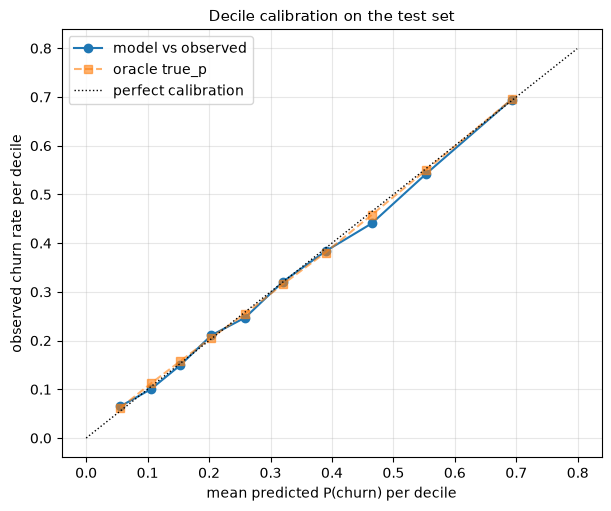

Well calibrated, as expected: the model family matches the data-generating process
and maximum likelihood is a proper scoring rule. Trees/boosting need a calibration
check far more often — see 04_ml_tabular/03_evaluation_calibration.ipynb.


In [26]:
# --- Solution 3 ---
deciles = (scored.withColumn("decile", F.ntile(10).over(Window.orderBy("p_churn")))
           .groupBy("decile")
           .agg(F.avg("p_churn").alias("mean_predicted"),
                F.avg("churn").alias("observed_churn"),
                F.avg("true_p").alias("oracle_p"),
                F.count("*").alias("n"))
           .orderBy("decile").toPandas())
print(deciles.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(deciles.mean_predicted, deciles.observed_churn, "o-", label="model vs observed")
ax.plot(deciles.mean_predicted, deciles.oracle_p, "s--", alpha=0.6, label="oracle true_p")
lims = [0, deciles.observed_churn.max() * 1.15]
ax.plot(lims, lims, "k:", lw=1, label="perfect calibration")
ax.set_xlabel("mean predicted P(churn) per decile")
ax.set_ylabel("observed churn rate per decile")
ax.set_title("Decile calibration on the test set")
ax.legend()
plt.show()
print("Well calibrated, as expected: the model family matches the data-generating "
      "process\nand maximum likelihood is a proper scoring rule. Trees/boosting need a "
      "calibration\ncheck far more often — see 04_ml_tabular/03_evaluation_calibration.ipynb.")

In [27]:
# Cleanup: temp model artifacts and the Spark session.
shutil.rmtree(MODEL_DIR, ignore_errors=True)
spark.stop()
print("done")

done
